In [1]:
from pathlib import Path
import numpy as np

import import_ipynb
import os
curdir = os.getcwd()
src_path = Path('../src/')
os.chdir(src_path)
from SummuryDataCollect import (collect_metrics_dataframe, plot_metrics_by_target, plot_model_feature_importance,
                                plot_dual_scenario_auto_aligned, plot_mean_std_auto_aligned)
os.chdir(curdir)

In [2]:
name3A = 'Scenario3_no_Aug'
name3B = 'Scenario3_full'

ROOT_PATH = Path('../processed_data/Results/')

Scenario3A_path = Path('../processed_data/Results/Scenario3_no_Aug/')
Scenario3B_path = Path('../processed_data/Results/Scenario3_full/')

metrics3A_paths = list(Scenario3A_path.glob('**/final_metrics.csv'))
metrics3B_paths = list(Scenario3B_path.glob('**/final_metrics.csv'))

m3A = collect_metrics_dataframe(metrics3A_paths, name3A)
m3B = collect_metrics_dataframe(metrics3B_paths, name3B)

name_list = [name3A, name3B]
df_list = [m3A, m3B]

models_names = ['Lasso', 'CatBoost', 'TreeBagging','MLP','CNN']

            Scenario3_no_Aug            


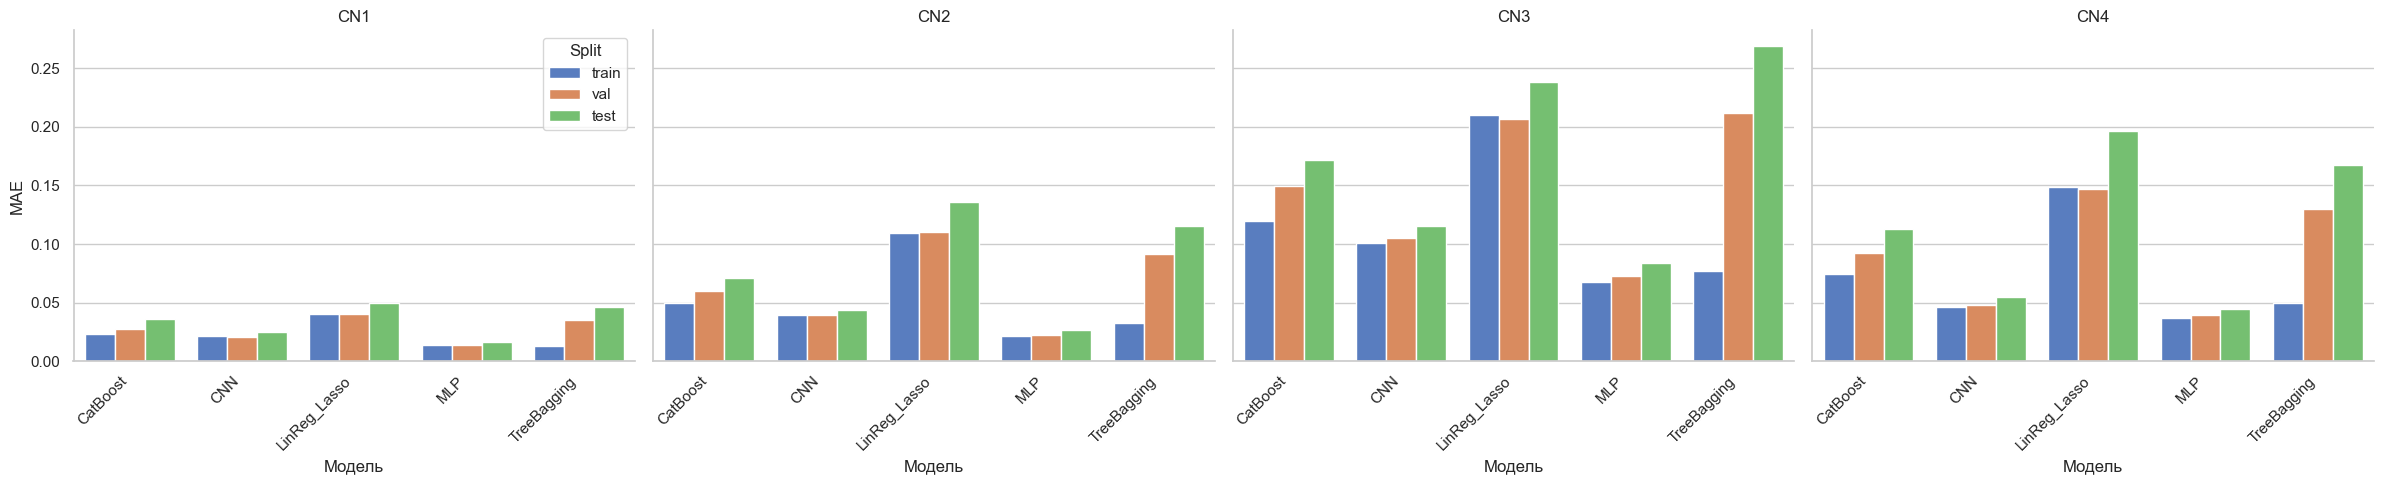

             Scenario3_full             


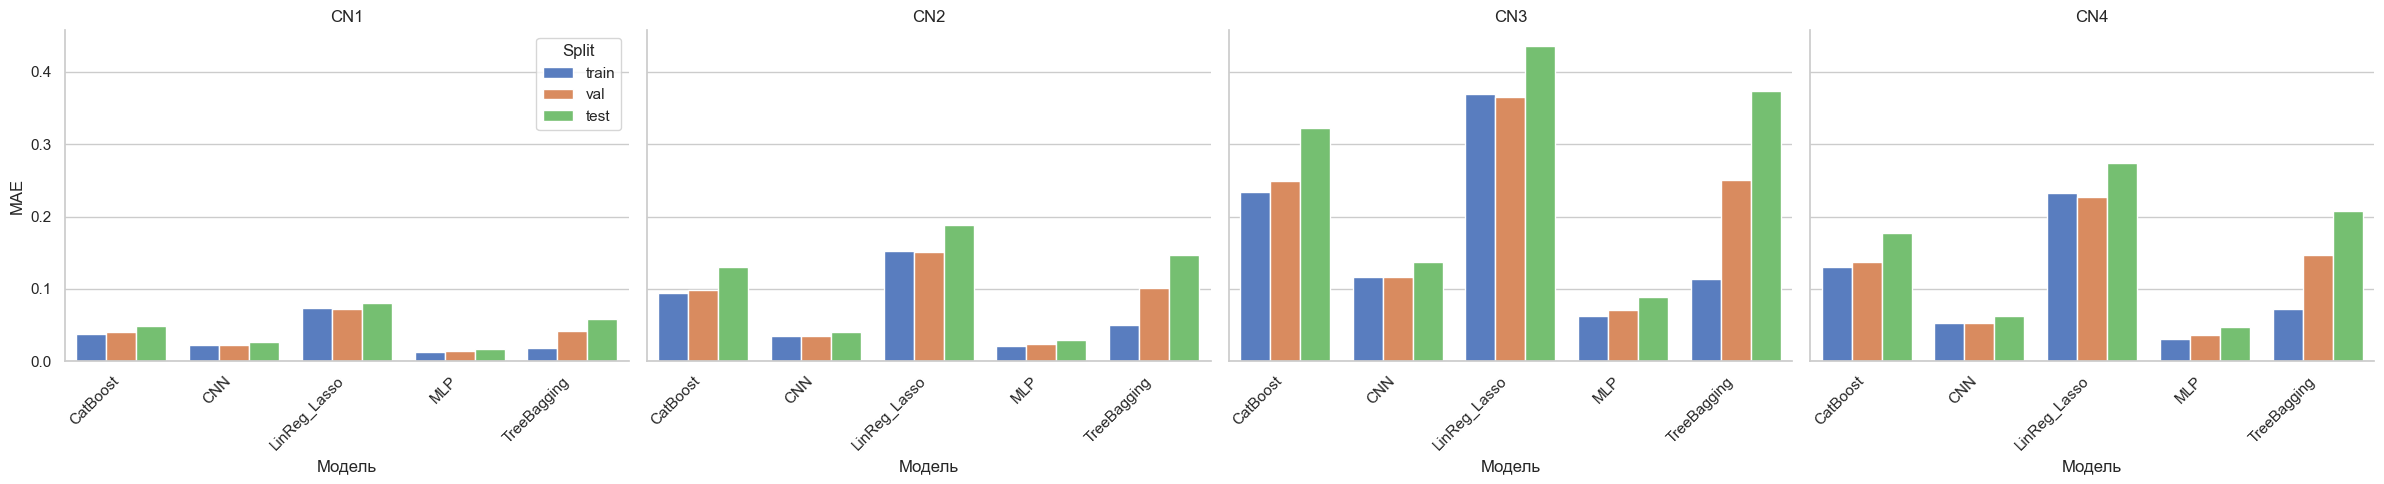

In [3]:
for name, df in zip(name_list, df_list):
    targets = ['CN1','CN2','CN3','CN4']
    metric = 'MAE'
    save_path = Path('../processed_data/Results/',name,f'{name}.png')
    print('='*40)
    print(f"{name:^40}")
    print('='*40)
    plot_metrics_by_target(df, metric_name=metric, target=targets, sharey=True, save_path=save_path)

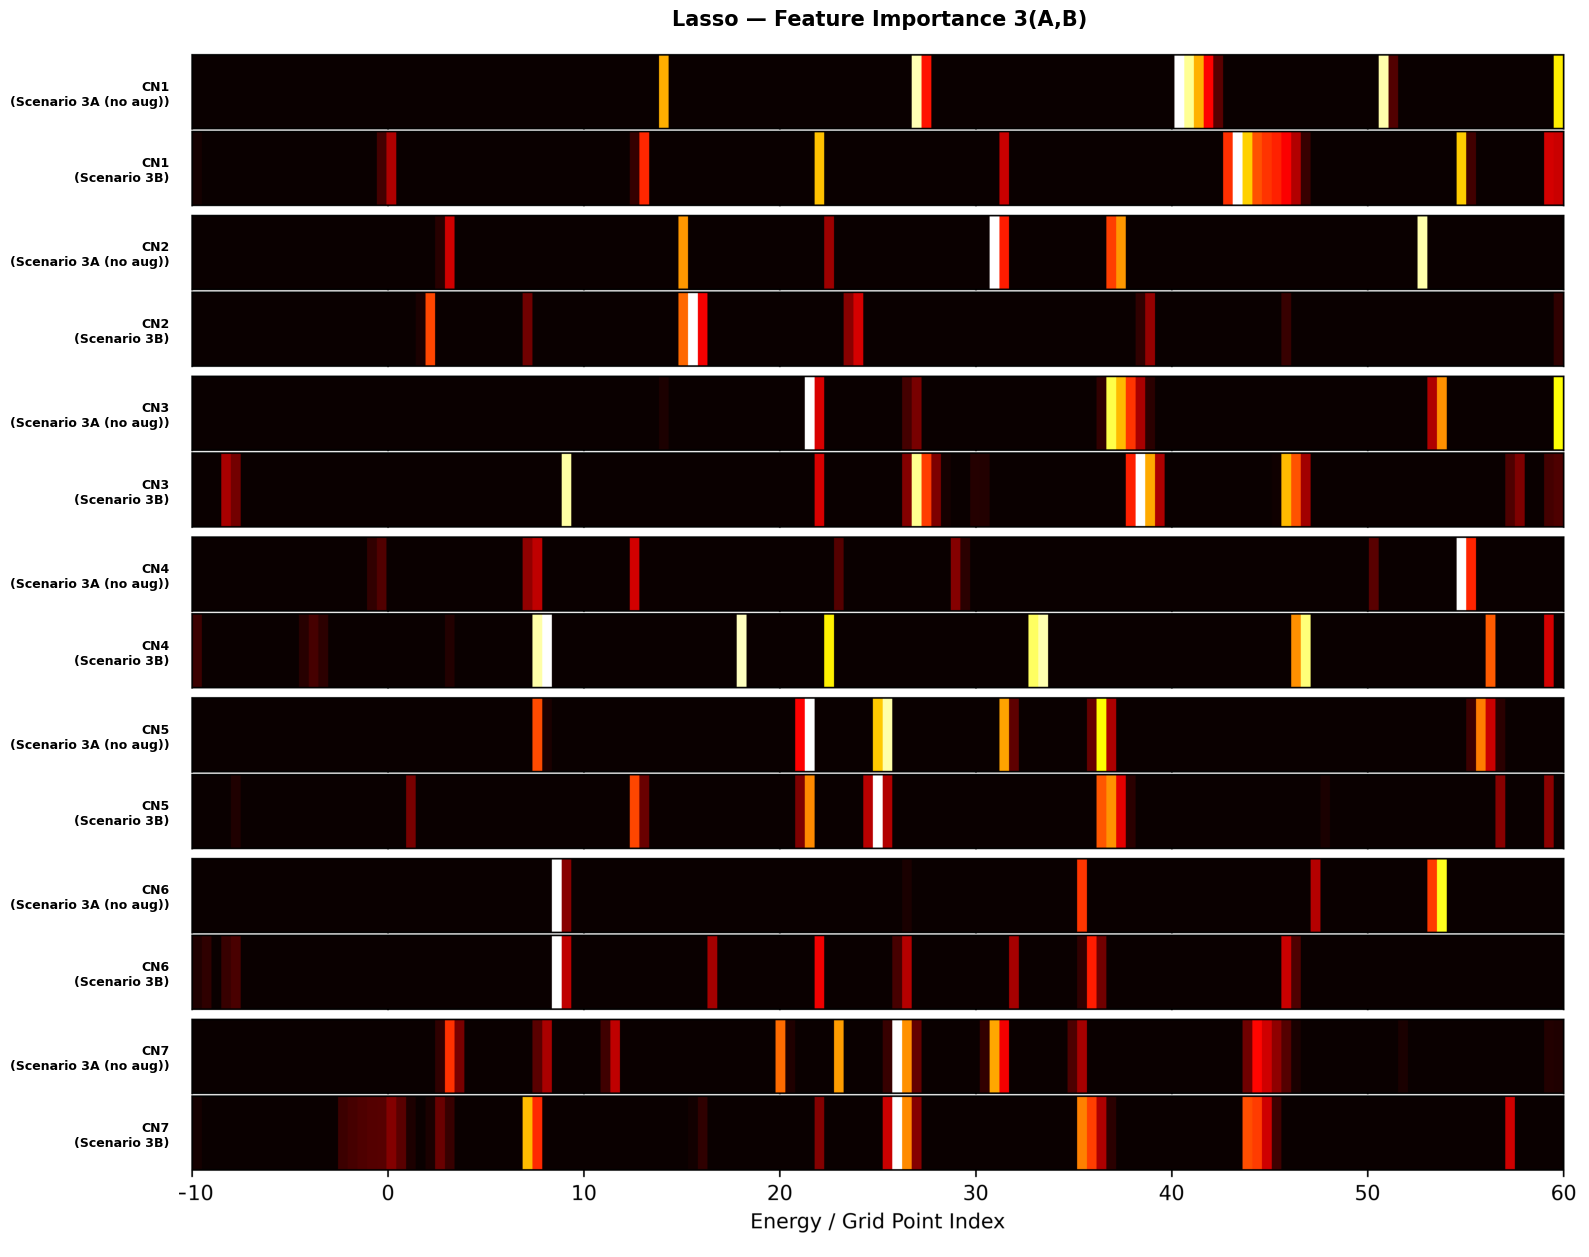

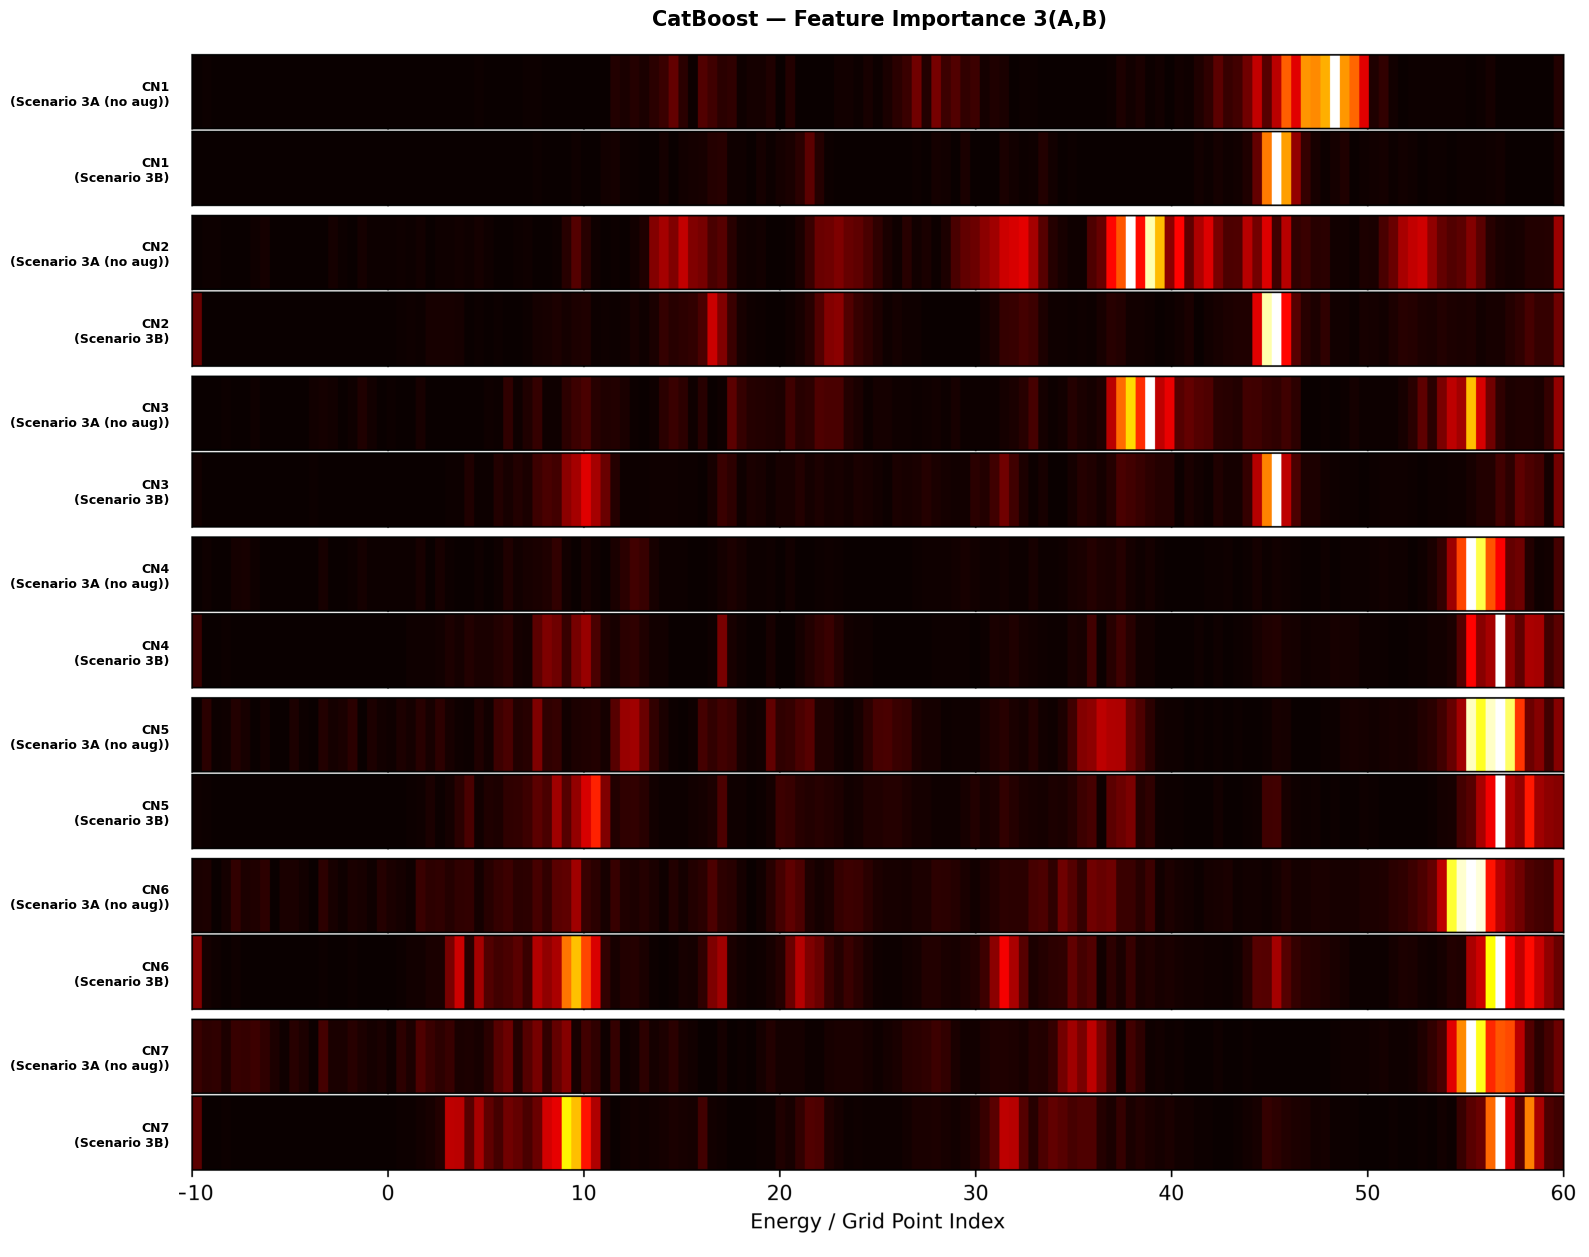

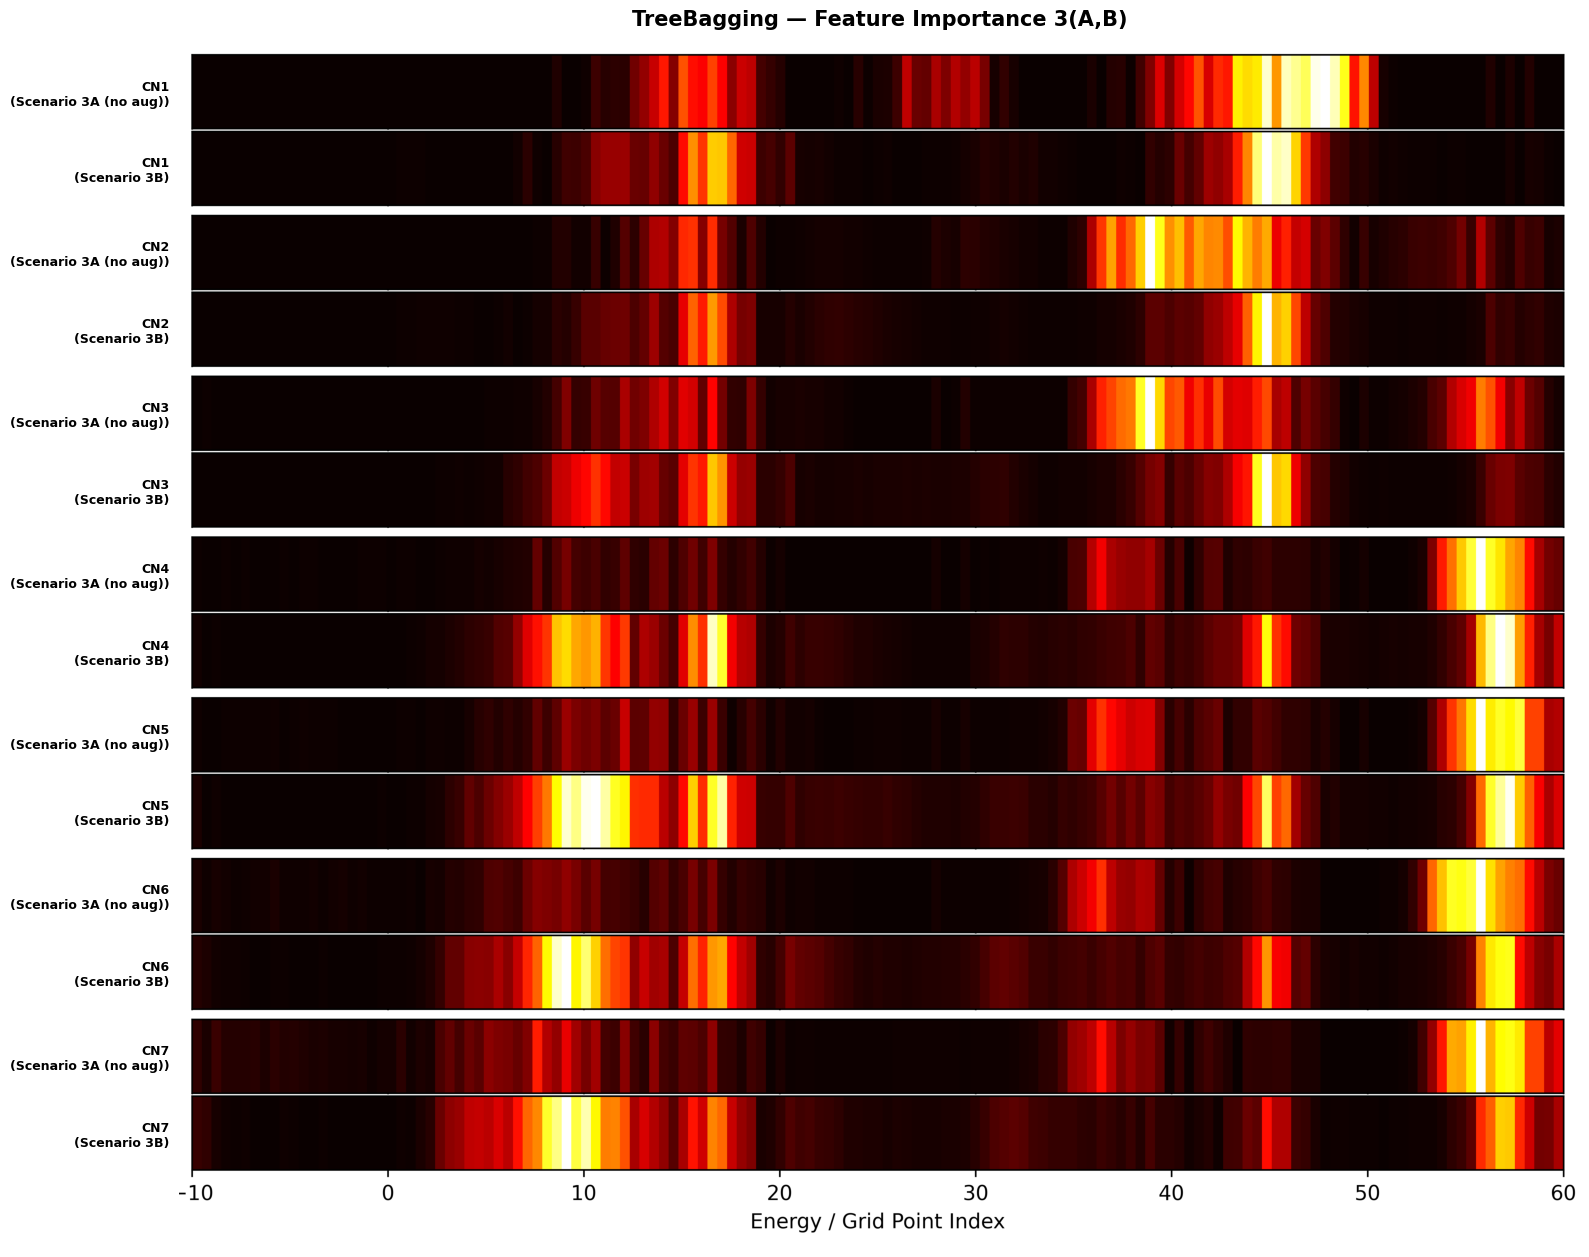

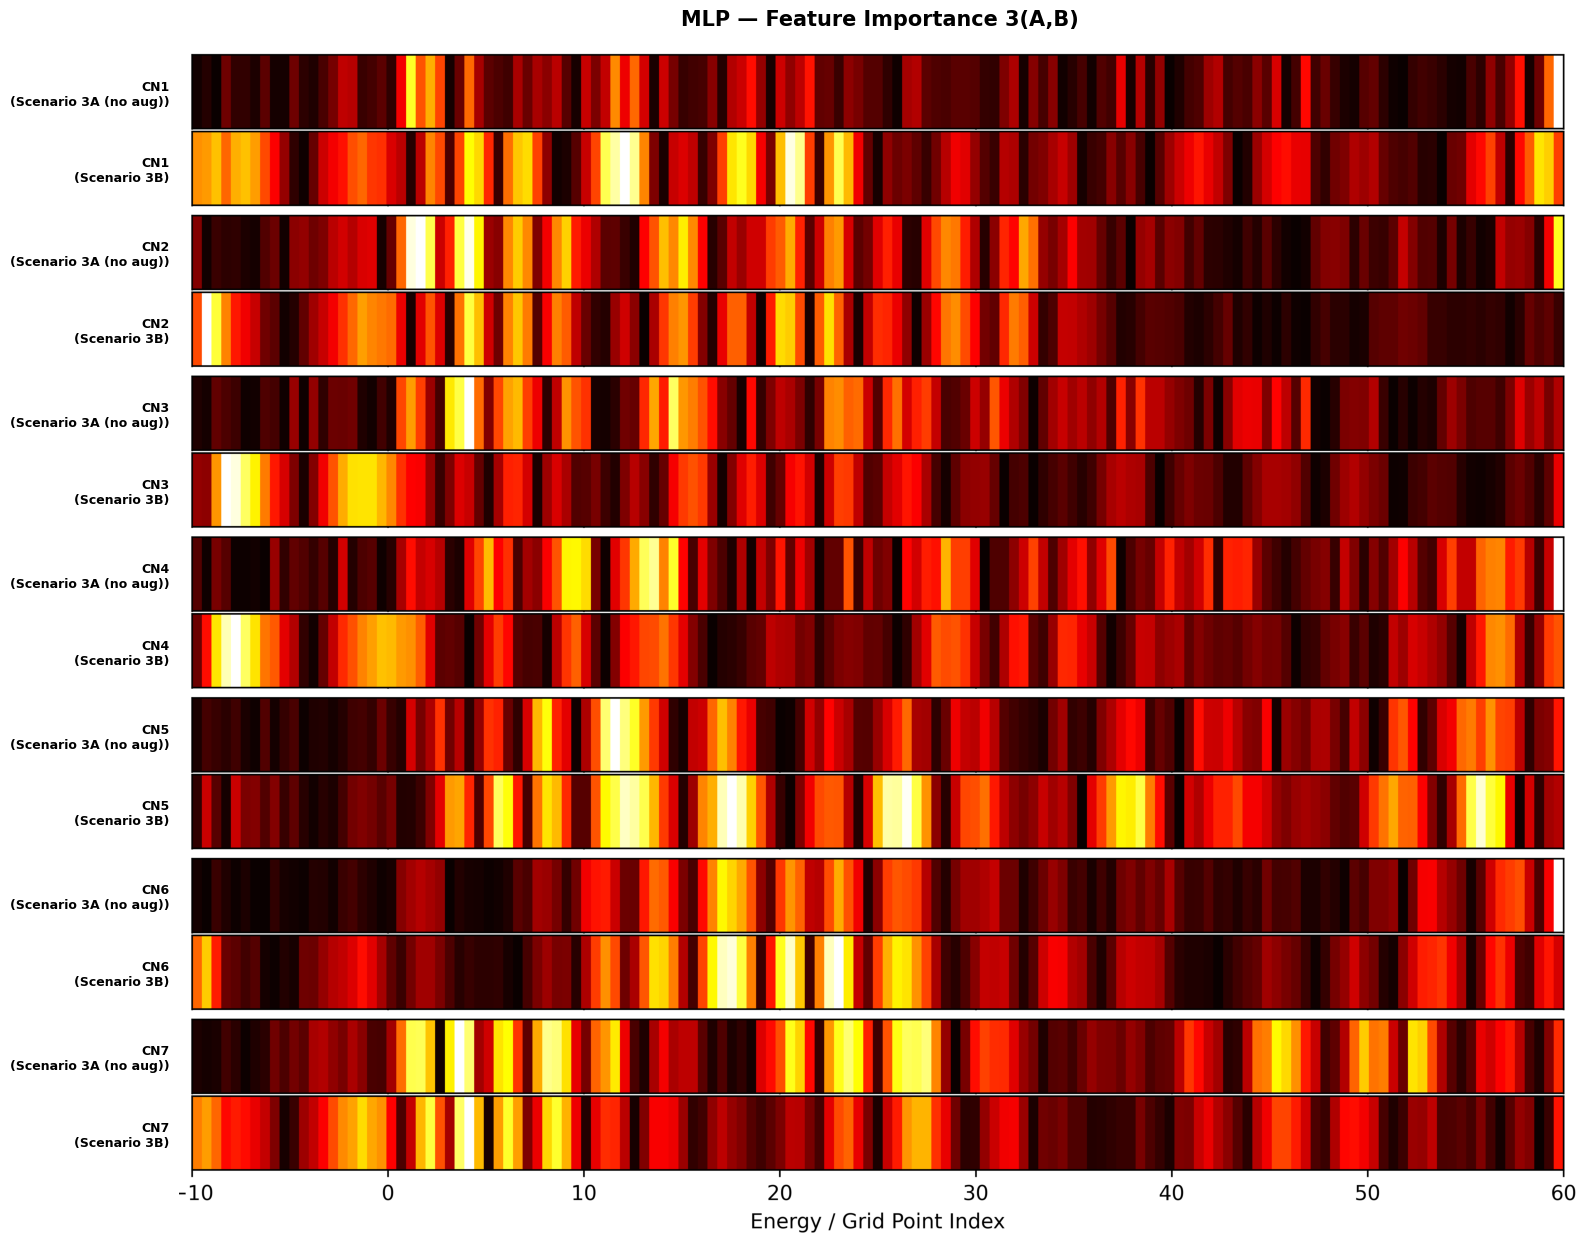

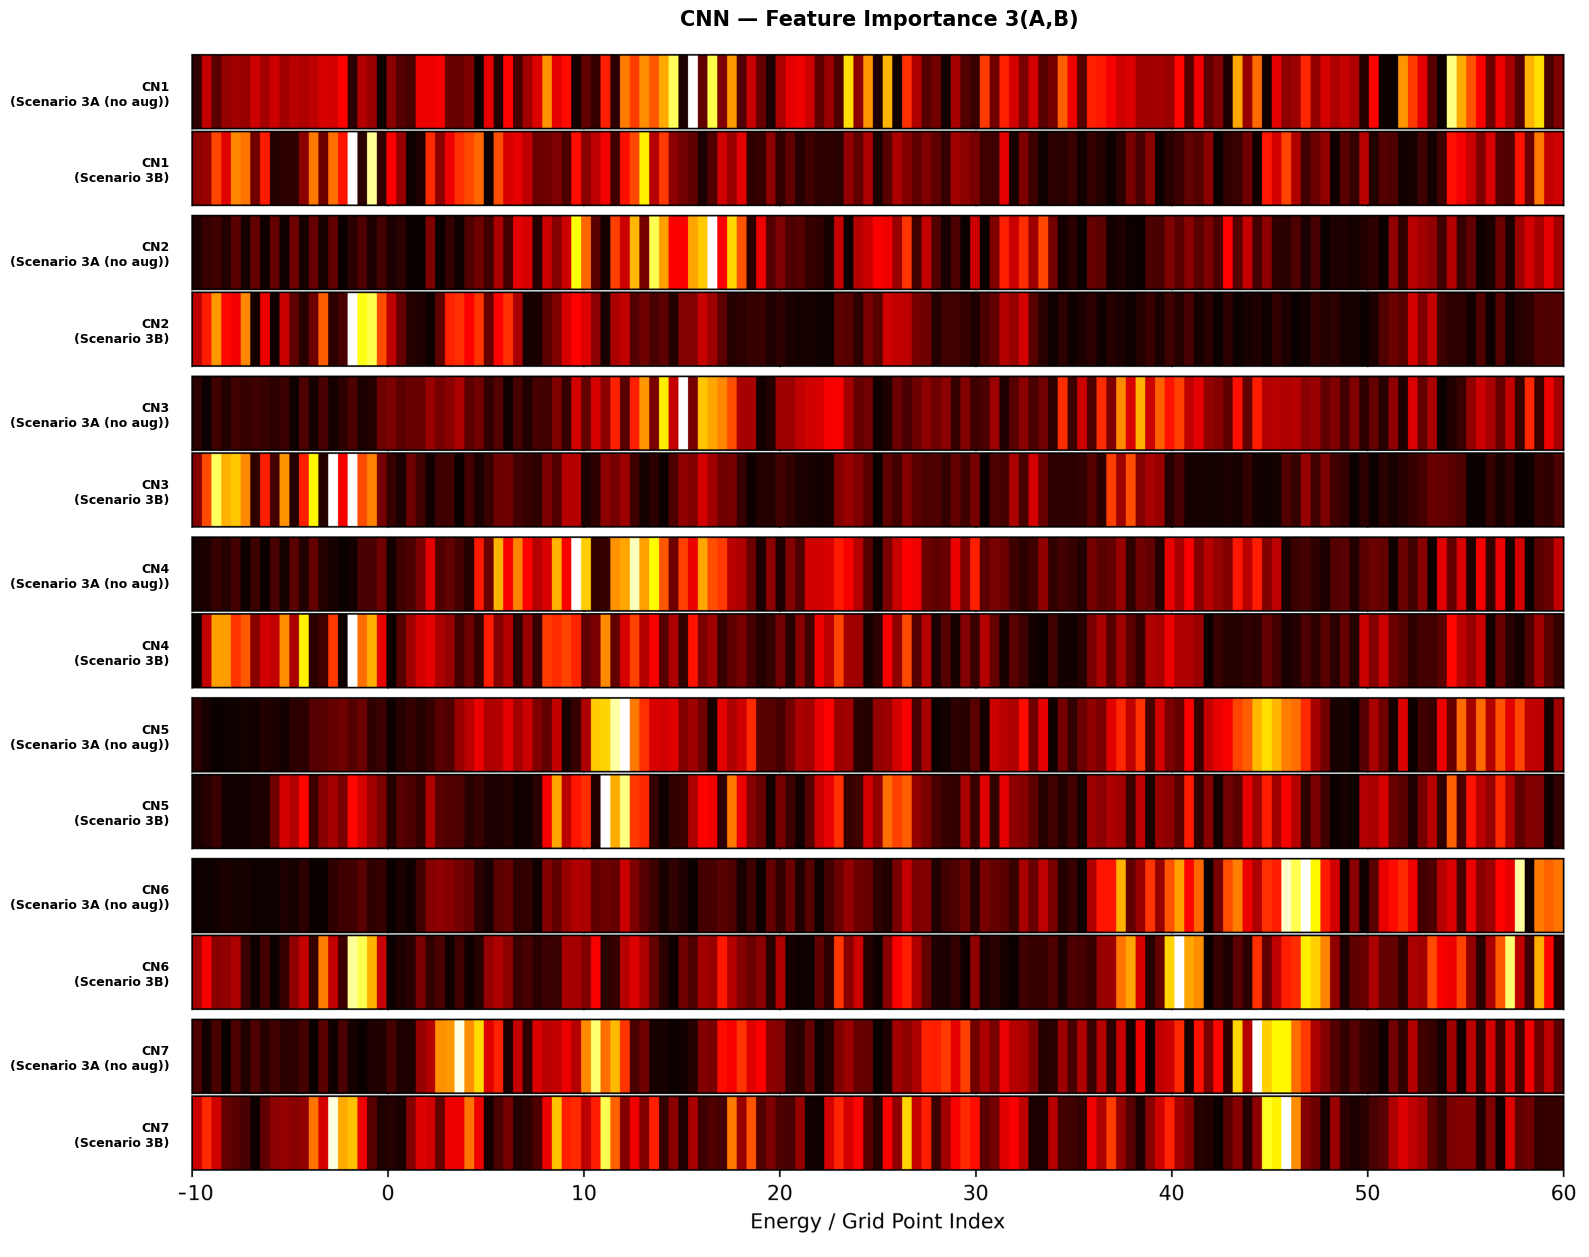

In [4]:
for m_name in models_names:
    for (a,b) in zip([name3A], [name3B]):
        path_a = list(ROOT_PATH.glob(f'**/{a}/**/{m_name}'))[0]
        path_b = list(ROOT_PATH.glob(f'**/{b}/**/{m_name}'))[0]
        save_path = Path(f'../processed_data/Results/FeatureMaps/{m_name}_Scenario_3.png')
        plot_dual_scenario_auto_aligned(path_scenario_a=path_a,
                                        path_scenario_b=path_b,
                                        model_title=f'{m_name} — Feature Importance 3(A,B)',
                                        label_a='Scenario 3A (no aug)',
                                        label_b='Scenario 3B',
                                        num_cn=7,
                                        separator_height = 30,
                                        save_path=save_path
                                       )

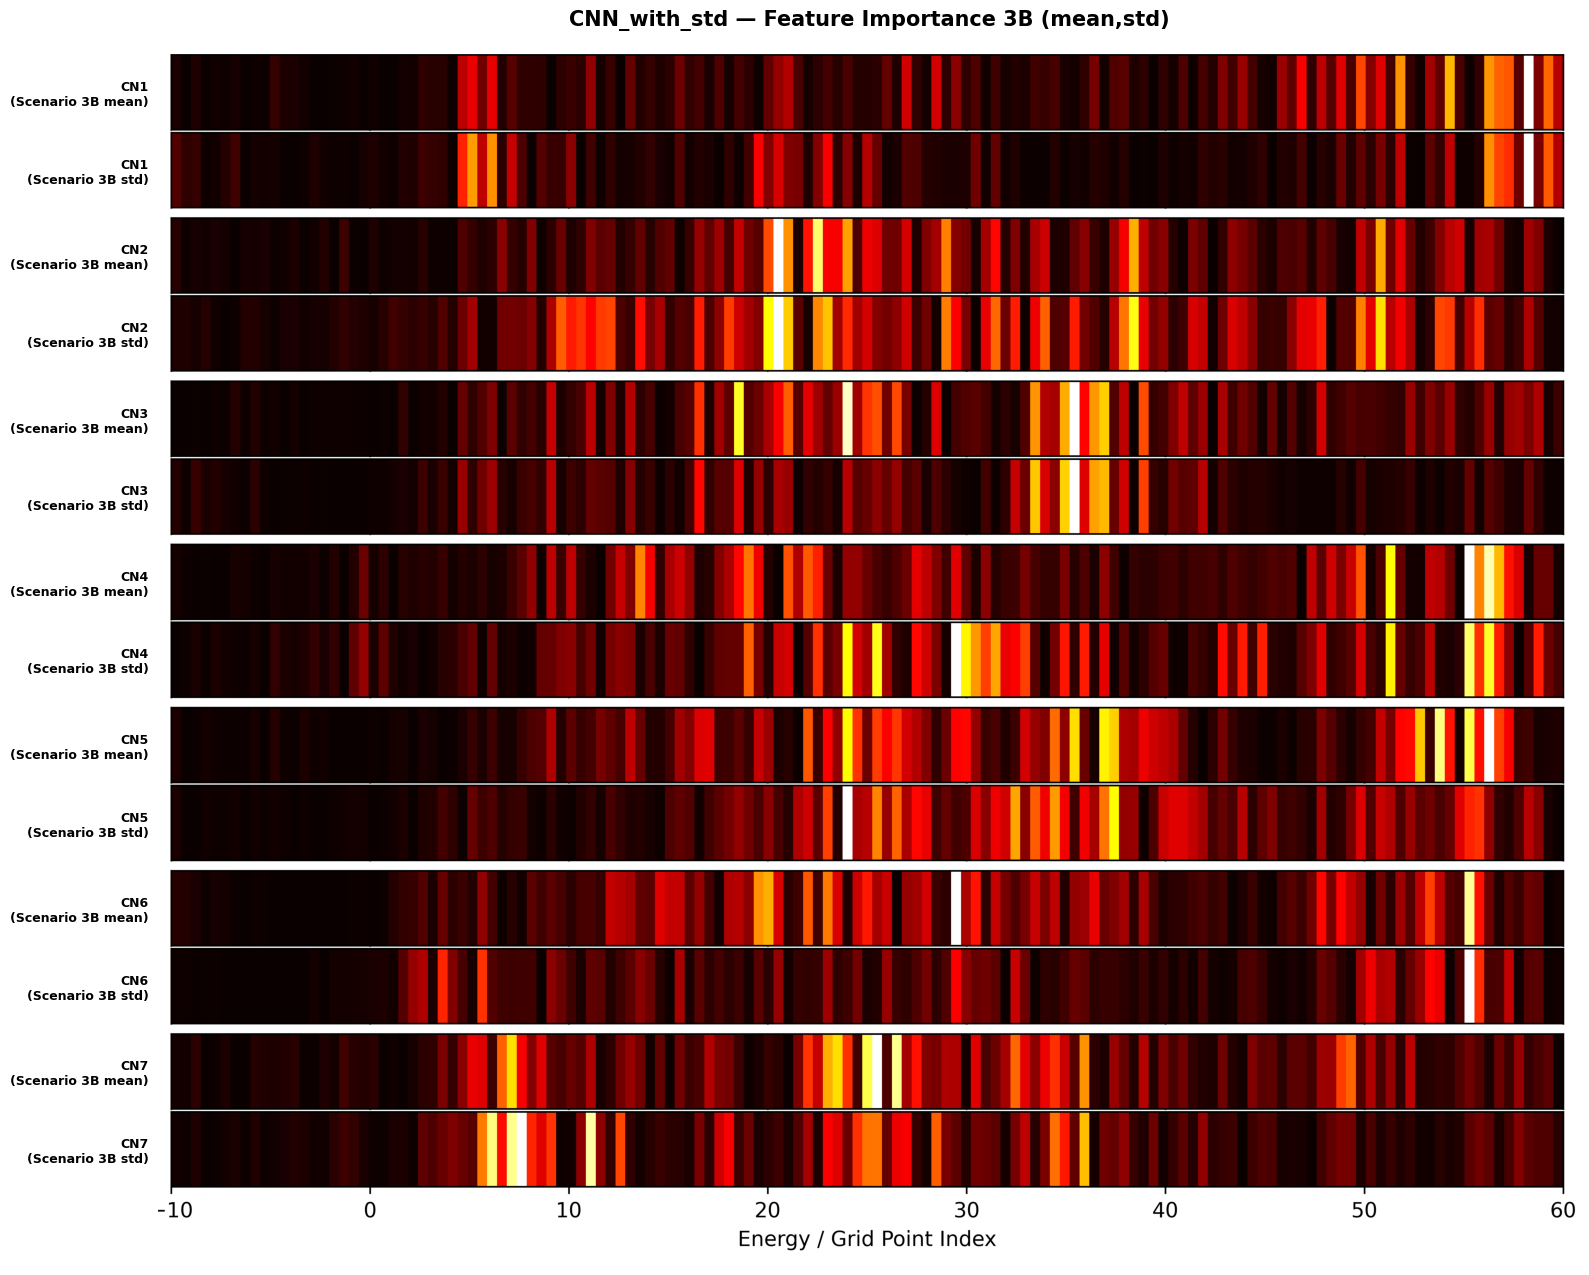

In [5]:
m_name = 'CNN_with_std'
for (a,b) in zip(['mean'], ['std']):
    path_a = list(ROOT_PATH.glob(f'**/{m_name}/**/{a}'))
    path_b = list(ROOT_PATH.glob(f'**/{m_name}/**/{b}'))
    path_a = sorted(path_a, key=lambda x: int(x.parent.name[-1]))
    path_b = sorted(path_b, key=lambda x: int(x.parent.name[-1]))
    save_path = Path(f'../processed_data/Results/FeatureMaps/{m_name}_Scenario_3.png')
    plot_mean_std_auto_aligned(paths_mean=path_a,
                               paths_std=path_b,
                               model_title=f'{m_name} — Feature Importance 3B (mean,std)',
                               label_a='Scenario 3B mean',
                               label_b='Scenario 3B std',
                               separator_height = 30,
                               save_path=save_path
                              )